## Dans ce notebook, nous verrons :
1. L'influence de l'apprentissage sur plusieurs capteurs
2. Comment entrainer notre modèle à débruiter un signal : on passera d'un Auto-Encodeur (AE) à un Denoising Auto-Encodeur (DAE)

In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1795185375.091727   13827 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, confusion_matrix
from keras.callbacks import EarlyStopping
from Sources import data, config, features, models

DUREE_FENETRE = config.DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=DUREE_FENETRE/2, recouvrement=0.5):
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = data.charger(nom, canaux=(canal,))
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"],
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "diametre_mils": info["diametre_mils"],
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def ajouter_bruit(x, snr_db, seed=42):
    rng = np.random.default_rng(seed)
    p = np.mean(x ** 2)
    return x + np.sqrt(p / 10 ** (snr_db / 10)) * rng.standard_normal(x.shape)

# --- DE + FE ---
selection_DE = data.selectionner(sources=("12kDE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("6",), charges=(0,1,2,3),
                                 canaux={"12kDE": ("DE",), "Normal": ("DE",)})
selection_FE = data.selectionner(sources=("12kFE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("3","6","12"), charges=(0,1,2,3),
                                 canaux={"12kFE": ("FE",), "Normal": ("FE",)})
SB_DE, infos_DE = construire_fenetres_brutes(selection_DE, canal="DE")
SB_FE, infos_FE = construire_fenetres_brutes(selection_FE, canal="FE")

SB = np.concatenate([SB_DE, SB_FE], axis=0)
infos = pd.concat([infos_DE, infos_FE], ignore_index=True)
SBNorm = StandardScaler().fit_transform(SB.T).T
print(SB.shape); print(infos.groupby(["canal", "defaut_sain"]).size())

(21944, 1200)
canal  defaut_sain
DE     Défaut         7269
       Sain           2825
FE     Défaut         9025
       Sain           2825
dtype: int64


In [6]:
groups = infos["fichier"] + "_" + infos["canal"]          # "Normal_L0_DE" ≠ "Normal_L0_FE"
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=40)
i_train, i_test = next(gss.split(infos, groups=groups))

sain = (infos["defaut_sain"] == "Sain").to_numpy()

i_sain_FE = np.where((infos["canal"] == "FE") & sain)[0]
i_test = np.union1d(i_test, i_sain_FE[: len(i_sain_FE) // 4])   # 25 % des sains FE au test
i_train = np.setdiff1d(np.arange(len(infos)), i_test)
X_train_sain = SBNorm[i_train][sain[i_train]]        # sains DE + FE du train

In [7]:
pd.DataFrame({
    "train": infos.iloc[i_train[sain[i_train]]][["defaut_sain","canal"]].value_counts(),
    "test":  infos.iloc[i_test][["defaut_sain","canal"]].value_counts(),
}).fillna(0).astype(int)

train  test
defaut_sain canal             
Défaut      DE         0  1817
            FE         0  2605
Sain        DE      2018   807
            FE      2119   706

In [8]:
def evaluer_par_capteur(modele, tag):
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)
    s_test, y = score[i_test], (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
    c = infos["canal"].to_numpy()[i_test]
    lignes = []
    for canal in ["DE", "FE"]:
        m = c == canal
        TN, FP, FN, TP = confusion_matrix(y[m], s_test[m] > seuil, labels=[0, 1]).ravel()
        lignes.append({"config": tag, "capteur": canal, "seuil_p99": round(float(seuil), 4),
                       "AUC": round(roc_auc_score(y[m], s_test[m]), 3),
                       "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})
    return pd.DataFrame(lignes)

modele_AE = models.conv1d_ae(SBNorm.shape[1])
modele_AE.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=50, batch_size=64,
              validation_split=0.1, verbose=1,
              callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_AE = evaluer_par_capteur(modele_AE, "AE (sains DE+FE)")
display(df_AE)

Epoch 1/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - loss: 0.3841 - val_loss: 0.2087
Epoch 2/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - loss: 0.0873 - val_loss: 0.0265
Epoch 3/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - loss: 0.0193 - val_loss: 0.0179
Epoch 4/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - loss: 0.0143 - val_loss: 0.0150
Epoch 5/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 163ms/step - loss: 0.0122 - val_loss: 0.0129
Epoch 6/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 12s 198ms/step - loss: 0.0111 - val_loss: 0.0118
Epoch 7/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 165ms/step - loss: 0.0101 - val_loss: 0.0110


,config,capteur,seuil_p99,AUC,FPR,FNR
0,AE (sains DE+FE),DE,0.037,1.0,0.0012,0.0
1,AE (sains DE+FE),FE,0.037,1.0,0.0000,0.0


In [9]:
# Data augmentation : on duplique le train sain bruité, cible = propre
X_aug, Y_aug = [X_train_sain], [X_train_sain]
for snr in [15, 10, 5, 0]:
    X_aug.append(ajouter_bruit(X_train_sain, snr, seed=snr))
    Y_aug.append(X_train_sain)
X_aug, Y_aug = np.concatenate(X_aug), np.concatenate(Y_aug)

modele_DAE = models.conv1d_ae(SBNorm.shape[1])
modele_DAE.fit(X_aug[..., None], Y_aug[..., None], epochs=50, batch_size=64,
               validation_split=0.1, verbose=1,
               callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_DAE = evaluer_par_capteur(modele_DAE, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

Epoch 1/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 42s 124ms/step - loss: 0.1464 - val_loss: 0.2416
Epoch 2/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 40s 139ms/step - loss: 0.0671 - val_loss: 0.2250
Epoch 3/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 42s 144ms/step - loss: 0.0626 - val_loss: 0.2195
Epoch 4/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 36s 123ms/step - loss: 0.0605 - val_loss: 0.2160
Epoch 5/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 36s 122ms/step - loss: 0.0592 - val_loss: 0.2138
Epoch 6/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 34s 117ms/step - loss: 0.0584 - val_loss: 0.2123
Epoch 7/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - loss: 0.0579 - val_loss: 0.2112
Epoch 8/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.0573 - val_loss: 0.2102


,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0153,1.0,0.0012,0.0
1,DAE (aug SNR 15..0),FE,0.0153,1.0,0.0014,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0370  1.0  0.0012  0.0
                    FE          0.0370  1.0  0.0000  0.0
DAE (aug SNR 15..0) DE          0.0153  1.0  0.0012  0.0
                    FE          0.0153  1.0  0.0014  0.0

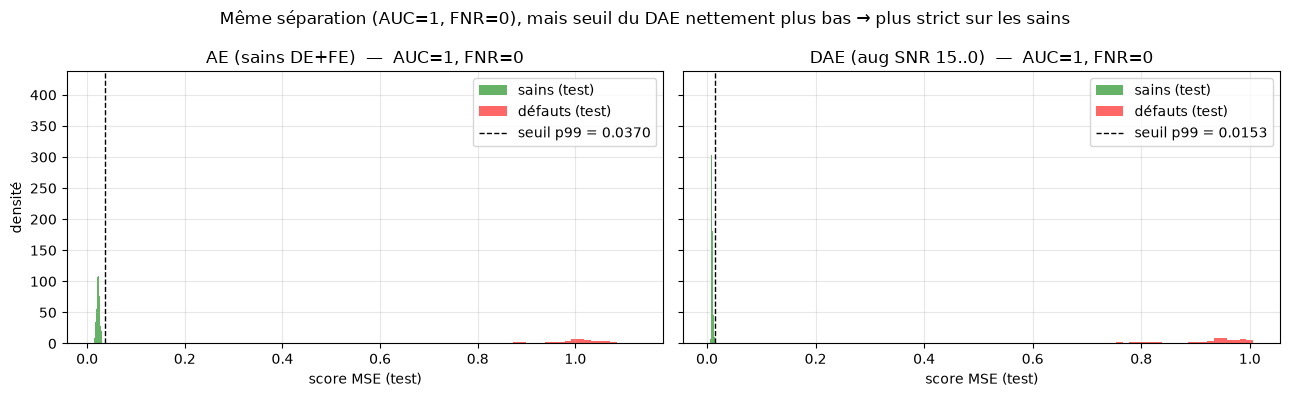

In [10]:
# === Illustration : seuil DAE plus bas, séparation identique ===
y_test = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, modele, tag in [(axes[0], modele_AE, "AE (sains DE+FE)"),
                        (axes[1], modele_DAE, "DAE (aug SNR 15..0)")]:
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)      # p99 du train sain
    s = score[i_test]
    ax.hist(s[~y_test], bins=60, density=True, alpha=0.6, color="green", label="sains (test)")
    ax.hist(s[y_test],  bins=60, density=True, alpha=0.6, color="red",   label="défauts (test)")
    ax.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil p99 = {seuil:.4f}")
    ax.set_title(f"{tag}  —  AUC=1, FNR=0"); ax.set_xlabel("score MSE (test)")
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("densité")
fig.suptitle("Même séparation (AUC=1, FNR=0), mais seuil du DAE nettement plus bas → plus strict sur les sains")
plt.tight_layout(); plt.show()

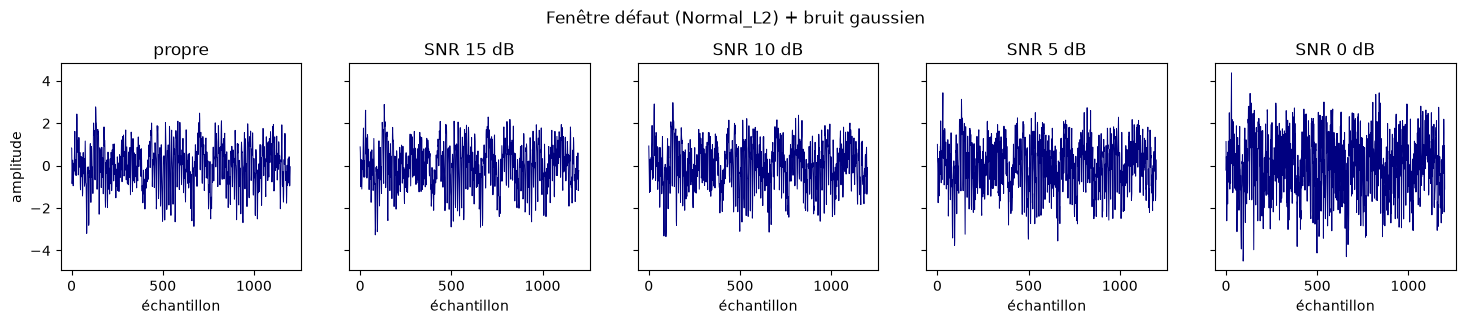

In [ ]:
#| label: fig-bruit
#| fig-cap: "Même fenêtre défaut à différents SNR (bruit gaussien ajouté) : propre, 15, 10, 5, 0 dB."
# i_def = i_test[~sain[i_test]][520]                 # une fenêtre défaut du test
i_def = i_test[sain[i_test]][0]                 # une fenêtre défaut du test
x = SBNorm[i_def]

niveaux = [None, 15, 10, 5, 0]                    # None = signal propre
titres  = ["propre", "SNR 15 dB", "SNR 10 dB", "SNR 5 dB", "SNR 0 dB"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharex=True, sharey=True)   # mêmes échelles
for ax, snr, titre in zip(axes, niveaux, titres):
    xb = x if snr is None else ajouter_bruit(x, snr, seed=42)   # même bruit reproductible
    ax.plot(xb, color="navy", lw=0.7)
    ax.set_title(titre); ax.set_xlabel("échantillon")
axes[0].set_ylabel("amplitude")
fig.suptitle(f"Fenêtre défaut ({infos.loc[i_def, 'fichier']}) + bruit gaussien")
plt.subplots_adjust(top=0.80)
plt.show()